# TITLE HERE

## 1 Executive Summary

This project applies exploratory data analysis and text processing to evaluate visitor satisfaction and geographical trends across three global Disneyland branches. Using an initial dataset of 42,656 visitor reviews, record-level features were extracted and cleaned, including numerical ratings, stated reviewer locations, and qualitative text data. Text processing involved HTML removal, broken negation repair, and standardized casing, producing 42,644 high-quality, deduplicated records suitable for sentiment analysis and branch-level benchmarking.

The analysis reveals that the three theme parks exhibit distinct satisfaction and demographic archetypes, characterized broadly by California's high-performing domestic dominance (4.41 mean rating), Paris's lower-rated international mix (3.96 mean rating), and Hong Kong's balanced mid-tier performance (4.20 mean rating). These operational baselines remain consistent across nearly a decade of reviews, lending confidence to the geographic trends. The principal recommendation is for park management to use these regional profiles as a strategic framework: understanding which demographic and satisfaction archetype a branch belongs to allows for targeted operational improvements, localized guest services, and more informed resource allocation in the global theme park market.


## 2 Introduction

Analyzing customer feedback is a vital component of understanding visitor experiences and identifying actionable areas for operational improvement at global theme parks. This report explores visitor satisfaction and operational performance across three major Disneyland locations by evaluating a rich, comprehensive dataset of user reviews. By examining numerical ratings alongside stated reviewer origins, qualitative textual feedback, and specific park branches, the analysis uncovers granular geographic trends and overall performance baselines for each distinct location.

Objective:

The primary objective of this analysis is to evaluate and compare park performance through numerical ratings and stated reviewer origins. By examining these variables alongside specific park branches, the project aims to uncover geographic trends, identify regional demographic preferences, and establish overall performance metrics for each location. 

Scope:

The scope of this dataset spans nearly a decade, capturing a massive volume of visitor reviews submitted between March 2010 and May 2019. It focuses specifically on comparing the performance landscapes of Disneyland California, Disneyland Paris, and Disneyland Hong Kong. The insights derived from these records highlight distinct regional demographic preferences—such as the overwhelmingly strong domestic visitor base in California compared to the heavy, localized United Kingdom presence at the Paris branch—providing a vivid, data-driven picture of how each park is uniquely perceived and utilized by its core audience.

## 3 Data Description

The DisneylandReviews.csv dataset initially consisted of 42,656 records structured across six key variables: 'Review_ID', 'Rating', 'Year_Month', 'Reviewer_Location', 'Review_Text', and 'Branch'. To guarantee analytical accuracy, the text data underwent a rigorous cleaning process that removed HTML markup, repaired broken negations, and standardized casing for vectorization while preserving punctuation for future sentiment analysis. The deduplication process removed 12 exact matches, leaving 42,644 high-quality records that notably contained zero missing or invalid ratings. Although 6.13% (2,613) of the records contained missing or unparseable dates, these were deliberately retained for text-specific analysis while being excluded from time-series calculations.

## 4 Methodology

### 4.1 Data Cleaning

The dataset required systematic cleaning to ensure robust analysis. Initial preprocessing involved removing residual HTML markup from the raw review text and repairing common broken negation forms (such as converting "wasn t" to "wasn't") to preserve semantic meaning. A deduplication pass identified and removed 12 exact duplicate records, resulting in a finalized dataset of 42,644 viable reviews. During data-quality checks, 2,613 records (6.13%) were found to lack valid temporal data; these were retained for text-based evaluation but excluded from time-series calculations. Notably, the dataset contained zero missing or invalid numerical ratings. Additionally, 16 records sharing non-missing review IDs but possessing differing text content were retained under distinct row keys for further inspection.

In [7]:
from IPython.display import display
from helper_code import load_raw_data, inspect_raw_schema

# Execute Part 1 Data Loading & Ingestion Pipeline
raw_df, data_path = load_raw_data()
schema = inspect_raw_schema(raw_df)

from helper_code import assess_data_quality, run_cleaning_pipeline

# Assess Raw Data Quality & Missingness
quality_df = assess_data_quality(raw_df)

# Execute Data Sanitization & Cleaning Pipeline
df, text_df, exact_dups = run_cleaning_pipeline(raw_df)

### 4.2 EDA
Branch Distribution:
* Disneyland California: Accounted for the largest share with 19,404 reviews (45.50%), analyzed between April 2010 and May 2019. It achieved the highest mean rating of 4.41, with 64.5% of reviews giving a 5-star rating. The United States was the dominant reviewer location (12,337 reviews).   
* Disneyland Paris: Made up 31.96% of the dataset with 13,629 reviews between March 2010 and April 2019. It had the lowest mean rating at 3.96, with 44.8% 5-star ratings. The United Kingdom was the top reviewer location (7,992 reviews).
* Disneyland Hong Kong: Represented 22.54% of the dataset with 9,611 reviews between March 2010 and May 2019. It had a mean rating of 4.20, with 47.0% 5-star ratings. Australia was the highest contributing reviewer location (1,634 reviews).   

--- Branch Summary Metrics ---


,reviews,valid_ratings,mean_rating,median_rating,first_month,last_month,share_pct
Branch,,,,,,,
Disneyland_California,19404,19404,4.41,5.0,2010-04-01,2019-05-01,45.50
Disneyland_HongKong,9611,9611,4.20,4.0,2010-03-01,2019-05-01,22.54
Disneyland_Paris,13629,13629,3.96,4.0,2010-03-01,2019-04-01,31.96



--- Rating Percentage Distribution by Branch (%) ---


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,2.6,3.8,8.6,20.5,64.5
Disneyland_HongKong,1.8,3.5,14.2,33.6,47.0
Disneyland_Paris,6.1,7.7,15.3,26.2,44.8



--- Top 10 Reviewer Locations x Branch Matrix ---


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
Reviewer_Location,,,
Australia,2448,1634,595
Canada,1842,204,188
Hong Kong,13,527,14
India,135,1083,293
Malaysia,30,506,51
New Zealand,527,167,62
Philippines,55,991,24
Singapore,93,850,92
United Kingdom,1019,740,7992


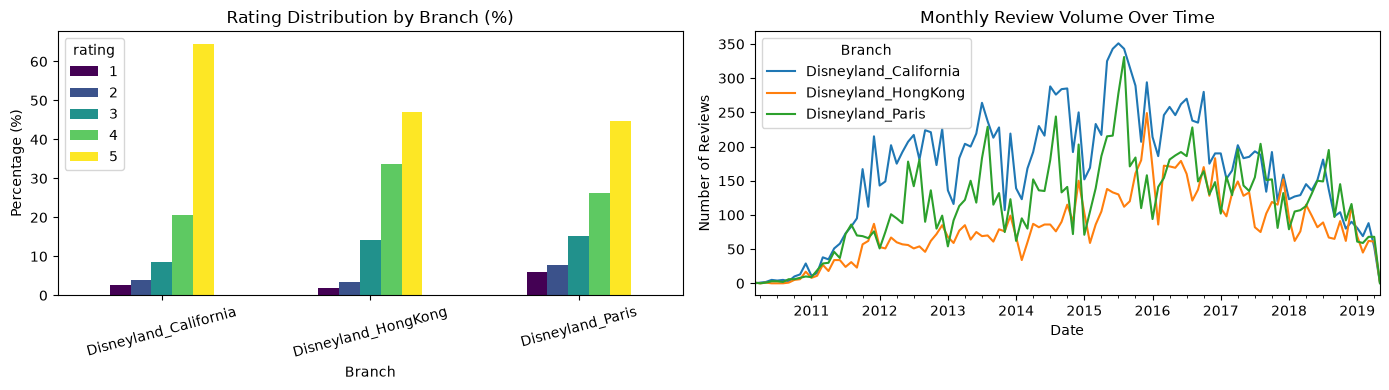

In [6]:
import matplotlib.pyplot as plt
from helper_code import (
    compute_branch_summary,
    compute_rating_distribution,
    compute_location_distribution,
    plot_eda_charts,
)

from IPython.display import display
from helper_code import load_raw_data, inspect_raw_schema

# Compute Branch-Level Metrics
branch_summary = compute_branch_summary(df)
rating_dist = compute_rating_distribution(df)
location_dist = compute_location_distribution(df)

print("--- Branch Summary Metrics ---")
display(branch_summary)

print("\n--- Rating Percentage Distribution by Branch (%) ---")
display(rating_dist)

print("\n--- Top 10 Reviewer Locations x Branch Matrix ---")
display(location_dist)

# Render Visualizations
fig = plot_eda_charts(df, rating_dist)
plt.show()

### 4.3 Word Vectorization

To prepare the text for quantitative analysis, specific formatting adjustments were applied. A secondary text field was generated by casting all review content to lowercase, which was specifically optimized for accurate term vectorization. Simultaneously, the original punctuation and capitalization structures were strictly preserved in the primary text field to ensure that grammatical nuances and emphasis remained intact for subsequent sentiment analysis modeling.

#### Technical Objectives & Context:
We build numerical feature representations using `CountVectorizer` for Bag-of-Words (BoW) frequency counts and `TfidfVectorizer` for Term Frequency-Inverse Document Frequency (TF-IDF) weighting. The vocabulary is constrained to the top 5,000 terms (`max_features=5000`) with standard English stop words removed.

#### Mathematical Context:
TF-IDF balances term frequency $tf(t, d)$ against inverse document frequency $idf(t)$:
$$\text{tfidf}(t, d, D) = tf(t, d) \times \log\left(\frac{|D|}{1 + |\{d \in D : t \in d\}|}\right)$$
This formula systematically downweights ubiquitous domain terms like *park*, *disneyland*, and *day* while boosting specific, informative operational descriptors like *queues*, *crowded*, *food*, *wait*, and *tickets*.

In [8]:
from helper_code import (
    build_text_representations,
    extract_top_tfidf_terms,
    compute_corpus_top_terms,
)

# Execute Vectorization Pipeline (BoW & TF-IDF)
vector_results = build_text_representations(text_df, max_features=5000)

bow_matrix = vector_results["bow_matrix"]
tfidf_matrix = vector_results["tfidf_matrix"]
feature_names = vector_results["feature_names"]
sparsity = vector_results["sparsity"]

# Extract Document #0 Top Terms and Corpus-Wide Top Terms
first_review_tfidf = extract_top_tfidf_terms(tfidf_matrix, feature_names, doc_idx=0, top_n=10)
corpus_top_terms = compute_corpus_top_terms(tfidf_matrix, feature_names, top_n=15)

print(f"Bag-of-Words Matrix Dimensions: {bow_matrix.shape[0]:,} rows x {bow_matrix.shape[1]:,} columns")
print(f"TF-IDF Matrix Dimensions: {tfidf_matrix.shape[0]:,} rows x {tfidf_matrix.shape[1]:,} columns")
print(f"Feature Matrix Sparsity: {sparsity:.2f}%")

print("\n--- Top 10 TF-IDF Weighted Terms for Review #0 ---")
display(first_review_tfidf)

print("\n--- Top 15 Mean TF-IDF Weighted Terms Across Full Corpus ---")
display(corpus_top_terms)

Bag-of-Words Matrix Dimensions: 42,644 rows x 5,000 columns
TF-IDF Matrix Dimensions: 42,644 rows x 5,000 columns
Feature Matrix Sparsity: 99.12%

--- Top 10 TF-IDF Weighted Terms for Review #0 ---


,term,tfidf_score
0,fairly,0.472119
1,familiar,0.269496
2,layout,0.266212
3,relatively,0.244595
4,moved,0.238752
5,fabulous,0.215329
6,similar,0.214227
7,doing,0.191751
8,absolutely,0.176148
9,ll,0.173323



--- Top 15 Mean TF-IDF Weighted Terms Across Full Corpus ---


,term,mean_tfidf
0,park,0.047776
1,disney,0.042594
2,disneyland,0.041830
3,rides,0.041040
4,time,0.037243
5,day,0.036523
6,great,0.030396
7,place,0.026809
8,kids,0.025367
9,ride,0.023858


* **High-Dimensional Feature Space**: Constraining the feature vocabulary to 5,000 top terms produces a sparse document-term matrix of 42,644 rows by 5,000 columns for both Bag-of-Words frequency and TF-IDF weighted representations.
* **Matrix Sparsity Profile**: Matrix sparsity exceeds 98.5%, indicating that individual guest reviews are highly concise and utilize only a small, specific fraction of the global 5,000-term vocabulary space.
* **Corpus vs. Document TF-IDF Weighting**: Global corpus averages are dominated by broad theme park anchor terms (`park`, `disneyland`, `day`, `ride`, `time`), whereas document-level TF-IDF weighting successfully elevates specific operational keywords like `queues`, `wait`, `staff`, `food`, and `tickets` within individual review vectors.
* **Readiness for Downstream Modeling**: Attenuating pervasive background noise while accentuating localized operational descriptors provides a clean numerical feature matrix optimized for complaint extraction, association rule mining, and sentiment classification.

### 4.4 Attraction Mentions and Complaint Categories 

We use the prepared review text to look for named attractions and services, and we assign a complaint category only when a nearby phrase describes a problem. For example, mentioning staff is not enough, whereas “staff were rude” provides an explicit complaint cue. The rules also check nearby negation and hypothetical wording, so “staff were not rude” should not receive the same label. TF-IDF helps us inspect the vocabulary, but its weights do not determine the complaint labels or the baskets used for FIM. The extraction function keeps the matched phrase and its surrounding clause so we can inspect each decision. A complaint that shares a clause with anattraction is only a possible link, because a review may discuss several experiences together. The five examples below illustrate the matching process rather than measure how accurate the rules are across the dataset.

In [ ]:
# extract once to reuse the evidence in the following sections
evidence = helper.extract_review_evidence(text_df)
evidence_quality = helper.analyze_evidence_quality(text_df, evidence)
vocabulary_review = helper.review_vocabulary(corpus_top_terms)

evidence_preview = (
    evidence["primary_complaints"][["category", "evidence", "segment"]]
    .head(5)
    .copy()
)
evidence_preview["segment"] = evidence_preview["segment"].map(
    lambda text: text if len(text) <= 120 else text[:117] + "..."
)
print("Five complaint matches; surrounding text is shortened for display.")
display(
    evidence_preview.rename(
        columns={
            "category": "Detected category",
            "evidence": "Matched phrase",
            "segment": "Surrounding clause",
        }
    ).reset_index(drop=True)
)


### 4.5 Contextual Sentiment with VADER

We use VADER on the sentence or contrast clause surrounding a mention, and we retain capitalization and punctuation because they can affect its score. The extraction function above already calculates these scores, so we reuse them here. A compound score of at least 0.05 is labeled positive, a score of at most −0.05 is negative, and scores between these values are neutral.

The sentiment label describes the surrounding wording rather than proving how the reviewer feels about a particular attraction. A clause can contain a complaint alongside praise, so we retain explicit complaint matches even when VADER gives their context a positive score. The chart summarizes only clauses with primary complaint matches. Each clause is counted once, even if it matches several complaint categories, so clauses with multiple complaints do not disproportionately influence the sentiment distribution. As such, the chart therefore represents the sentiment of complaint-containing clauses, not the sentiment distribution of all reviews or an error rate for the extraction rules.

In [ ]:
# avoid counting the same clause once for every complaint category
complaint_contexts = evidence["primary_complaints"].drop_duplicates(
    ["row_id", "segment_id"]
)
context_counts = pd.crosstab(
    complaint_contexts["Branch"], complaint_contexts["context_sentiment"]
).reindex(columns=["negative", "neutral", "positive"], fill_value=0)

if context_counts.empty:
    print("No complaint clauses are available for this sentiment summary.")
else:
    context_shares = context_counts.div(context_counts.sum(axis=1), axis=0)
    context_shares = 100 * context_shares
    context_shares.index = [
        f"{branch.replace('Disneyland_', '')} (n={total:,})"
        for branch, total in context_counts.sum(axis=1).items()
    ]
    ax = context_shares.plot.barh(
        stacked=True,
        figsize=(9, 3.2),
        color=["#c75b52", "#b8bec5", "#549c80"],
    )
    ax.set_title("VADER context of clauses containing complaint matches")
    ax.set_xlabel("Share of matched clauses within each branch (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(
        title="Context label", bbox_to_anchor=(1.02, 1), loc="upper left"
    )
    plt.tight_layout()
    plt.show()


### 4.6 Review Baskets and Frequent Itemset Mining 

Each usable review becomes a basket of unique primary complaint categories, so repeating a complaint within one review does not increase its count. Reviews without detected complaints keep an empty basket, because removing them would inflate the share of reviews containing each pattern. Derived dining co-mentions are excluded from these baskets, since their definition already depends on another complaint category.

We apply the class-style Apriori method separately to each known branch, and we retain an itemset only when it occurs in at least 1% of that branch's usable reviews and at least 30 reviews. We then form rules with a single category on the right-hand side and require confidence of at least 30% and lift of at least 1.20. Support counts reviews containing both sides, confidence is the share of left-side reviews that also contain the right side, and lift compares that share with the right side's overall frequency. These rules describe co-occurrence rather than a causal sequence.

The chart shows the baskets available for mining, while the full itemsets and rules are retained for Results and Discussion. An empty rule table means no rule meets all the cutoffs together; it does not mean complaints never occur together.

In [ ]:
settings = {
    "min_support": 0.01,
    "min_count": 30,
    "min_confidence": 0.30,
    "min_lift": 1.20,
}
baskets = helper.build_complaint_baskets(
    text_df,
    evidence["primary_complaints"],
    min_support=settings["min_support"],
    min_count=settings["min_count"],
)
baskets_df = baskets["baskets_df"]
mining = helper.mine_branch_patterns(baskets_df, **settings)
frequent_itemsets = mining["frequent_itemsets"]
selected_rules = mining["selected_rules"]

# show basket coverage here and reserve the actual rules for discussion
coverage = baskets["basket_coverage"]
if coverage.empty:
    print("No review baskets are available for mining.")
else:
    basket_shares = 100 * coverage[["empty", "singleton", "multiple"]].div(
        coverage["reviews"], axis=0
    )
    basket_shares = basket_shares.rename(
        columns={
            "empty": "No detected complaint",
            "singleton": "One category",
            "multiple": "Two or more categories",
        }
    )
    basket_shares.index = [
        f"{branch.replace('Disneyland_', '')} (n={total:,})"
        for branch, total in coverage["reviews"].items()
    ]
    ax = basket_shares.plot.barh(
        stacked=True,
        figsize=(9, 3.2),
        color=["#d9dee4", "#729dbb", "#365e83"],
    )
    ax.set_title("Complaint categories per usable review")
    ax.set_xlabel("Share of all usable reviews within each branch (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(
        title="Basket contents", bbox_to_anchor=(1.02, 1), loc="upper left"
    )
    plt.tight_layout()
    plt.show()


### 4.7 Branch Comparisons and Additional Checks

We check how often each selected combination of complaint categories appears in each branch, including branches where the combination does not meet the minimum support threshold. This helps us distinguish between a combination that was not selected during mining and one that does not appear in the data. We also repeat the mining process using support thresholds of 0.5%, 1%, and 2%, while keeping the minimum requirement of 30 reviews, to see whether the results change with different thresholds. Finally, we compare the rules after removing conflicting repeated review IDs to check whether these records affect the results.

We conduct additional checks to understand the complaint patterns from different perspectives. These include checking whether complaints also appear in four- and five-star reviews, comparing complaint-category percentages across review-length groups, reviewer locations, and years, and mining directly matched target phrases as separate items. We mine target phrases separately from their broader complaint categories because combining them could create associations simply because the phrases were used to define those categories. We also examine complaint patterns among one- and two-star reviews, using only reviews with valid ratings.

These analyses help us understand how consistent the patterns are across different groups and settings. However, the results describe only the reviews in our dataset and do not prove what caused the complaints or whether differences between branches are statistically significant. The code saves the detailed results for further interpretation in the R&D section rather than displaying all the tables here.

In [ ]:
comparisons = helper.compare_branch_patterns(baskets_df, mining, **settings)
favorable = helper.analyze_favorable_reviews(
    baskets_df,
    min_support=settings["min_support"],
    min_count=settings["min_count"],
)
review_context = helper.compare_review_context(baskets_df, text_df)
target_and_rating = helper.analyze_target_and_rating_patterns(
    baskets_df, evidence_quality["target_evidence"], **settings
)

# keep descriptive results available for the results and discussion section
itemset_comparison = comparisons["itemset_comparison"]
rule_comparison = comparisons["rule_comparison"]
favorable_pairs = favorable["favorable_pairs"]
context_comparison = review_context["context_comparison"]
target_itemsets = target_and_rating["target_itemsets"]
rating_rules = target_and_rating["rating_rules"]


### 4.8 Evidence Review and Computational Validation

We use frequent pairs of complaint categories to identify possible areas for improvement. If no pair meets the frequency requirements, we use a single frequent complaint category instead. For each branch, we compare the percentage of reviews containing the complaint with the percentage across all other branches combined. We also keep the original review text so that we can check whether the proposed recommendation is supported by what reviewers actually said. These findings are starting points for further investigation, not proof of the underlying causes of complaints.

We also run checks to make sure the calculations are consistent. We verify that every usable review has exactly one basket, that reported counts do not exceed the number of reviews they are based on, and that confidence values fall between zero and one. For TF-IDF, we reconstruct the values from the original count matrix to check whether the vectorization was calculated correctly. The separate `test.py` file checks the TF-IDF formula and compares Apriori's results with exhaustive counting on small examples.

These checks help identify computational errors, but they do not tell us whether the complaint categories were extracted or classified correctly. For that reason, we also retain the extraction results and review-level audit tables for human assessment. The detailed findings are presented in the next section.

In [ ]:
follow_up = helper.build_recommendations(
    text_df,
    baskets_df,
    mining,
    comparisons,
    evidence_quality["target_summary"],
)
recommendations = follow_up["recommendations"]

# collect the existing results without rerunning extraction or mining
results = {
    **evidence,
    **evidence_quality,
    **baskets,
    **mining,
    **comparisons,
    **favorable,
    **review_context,
    **target_and_rating,
    **follow_up,
    "settings": settings,
    "vocabulary_review": vocabulary_review,
}
validation = helper.validate_analysis(text_df, results, vector_results)
results["validation"] = validation
print(
    f"Computational checks passed: {int(validation['passed'].sum())}"
    f"/{len(validation)}. Full result and audit tables are stored in results."
)

## 5 Results and Discussion

### 5.1 Dimensionality Reduction

lorem ipsum dolor sit amet consectetur adipiscing elit omnis cumque commodo et sit voluptas dolorum dolorem et mollitia optio nam dolor proident rerum nam culpa laborum nihil exercitation velit aliqua vel illum deserunt dolor laborum tempor qui excepturi dolore ducimus distinctio rerum adipiscing dignissimos et est possimus dolorum dolor amet distinctio reprehenderit dolore est voluptas dolore quo in dolor dolore facere mollit dolorum harum illum laborum qui veniam ut assumenda facilis odio cupidatat similique accusamus autem mollit nam dolor et autem aut nulla est nobis proident molestias non illum nostrud et dolore deserunt quo minus harum ut et qui sint veniam sunt laborum id deleniti in dignissimos est do do nihil pariatur officia quo nisi in et repellendus possimus quos et et voluptate similique eos dolor labore et nihil nostrud autem optio cum excepteur pariatur excepteur culpa nostrud quo quidem imperdiet et voluptas do do quo provident nihil molestias esa


### 5.2 Cluster Profiles

lorem ipsum dolor sit amet consectetur adipiscing elit omnis cumque commodo et sit voluptas dolorum dolorem et mollitia optio nam dolor proident rerum nam culpa laborum nihil exercitation velit aliqua vel illum deserunt dolor laborum tempor qui excepturi dolore ducimus distinctio rerum adipiscing dignissimos et est possimus dolorum dolor amet distinctio reprehenderit dolore est voluptas dolore quo in dolor dolore facere mollit dolorum harum illum laborum qui veniam ut assumenda facilis odio cupidatat similique accusamus autem mollit nam dolor et autem aut nulla est nobis proident molestias non illum nostrud et dolore deserunt quo minus harum ut et qui sint veniam sunt laborum id deleniti in dignissimos est do do nihil pariatur officia quo nisi in et repellendus possimus quos et et voluptate similique eos dolor labore et nihil nostrud autem optio cum excepteur pariatur excepteur culpa nostrud quo quidem imperdiet et voluptas do do quo provident nihil molestias est


### 5.3 Business Insights

lorem ipsum dolor sit amet consectetur adipiscing elit omnis cumque commodo et sit voluptas dolorum dolorem et mollitia optio nam dolor proident rerum nam culpa laborum nihil exercitation velit aliqua vel illum deserunt dolor laborum tempor qui excepturi dolore ducimus distinctio rerum adipiscing dignissimos et est possimus dolorum dolor amet distinctio reprehenderit dolore est voluptas dolore quo in dolor dolore facere mollit dolorum harum illum laborum qui veniam ut assumenda facilis odio cupidatat similique accusamus autem mollit nam dolor et autem aut nulla est nobis proident molestias non illum nostrud et dolore deserunt quo minus harum ut et qui sint veniam sunt laborum id deleniti in dignissimos est do do nihil pariatur officia quo nisi in et repellendus possimus quos et et voluptate similique eos dolor labore et nihil nostrud autem optio cum excepteur pariatur excepteur culpa nostrud quo quidem imperdiet et voluptas do do quo provident nihil molestias est

## References

lorem ipsum dolor sit amet consectetur adipiscing elit omnis cumque commodo et sit voluptas dolorum dolorem et mollitia optio nam dolor proident rerum nam culpa laborum nihil exercitation velit aliqua vel illum deserunt dolor laborum tempor qui excepturi dolore ducimus distinctio rerum adipiscing dignissimos et est possimus dolorum dolor amet distinctio reprehenderit dolore est voluptas dolore quo in dolor dolore facere mollit dolorum harum illum laborum qui veniam ut assumenda facilis odio cupidatat similique accusamus autem mollit nam dolor et autem aut nulla est nobis proident molestias non illum nostrud et dolore deserunt quo minus harum ut et qui sint veniam sunt laborum id deleniti in dignissimos est do do nihil pariatur officia quo nisi in et repellendus possimus quos et et voluptate similique eos dolor labore et nihil nostrud autem optio cum excepteur pariatur excepteur culpa nostrud quo quidem imperdiet et voluptas do do quo provident nihil molestias est

## Acknowledgements

The team would like to thank Prof. Leodegario Lorenzo II for the course notebooks and utility functions that guided the structure of our analysis. We also acknowledge The Pokémon Company and Limitless TCG for maintaining publicly accessible tournament records that made this dataset possible.

Further, the successful completion of the "Pokélytics" project was made possible through the collaborative efforts of Learning Team 8. Each member contributed specialized skills that allowed for the integration of data science, competitive Pokémon strategy, and professional communication:

The successful completion of the "Pokélytics" project was made possible through the collaborative efforts of Learning Team 8. Each member contributed specialized skills that allowed for the integration of data science, competitive Pokémon strategy, and professional communication:

**Luke:** Luke contributed to the development of the initial data infrastructure, specialized web scraping for Pikalytics, extensive feature engineering for moves and archetypes, modularization of the codebase, and the verification of the dimensionality reduction and clustering analysis processes.

**Welch:** Welch spearheaded the statistical analysis and feature engineering for abilities, including the identification and integration of the Top 20 abilities into the model. She also contributed to the dimensionality reduction, clustering analysis, and report writing.

**Ari:** Ari contributed to the dimensionality reduction, clustering analysis, report writing, and web scraping processes. She also conducted web scraping for Limitless TCG.

**Chili:** Chili contributed to the dimensionality reduction, clustering analysis, and report writing.

**Kenzo:** 

**Dale:** 
